# 01 – Plant AE Channel Analysis

> **Historical dataset note:** This notebook documents the passive 2026-06-22 setup; it does not describe the active Pico sweep wiring from 2026-06-29 (CH1=GP14 marker, CH3/CH4=calibrated Stahl+LM358+830 kΩ probe heads).

First look at the three measurement channels of the plant AE setup.
Canonical high-resolution dataset:
`data/long_captures/20260622_163645/raw` (20 captures per channel, 500 kSa/s,
300 000 points, 0.6 s, 1.67 Hz resolution).

The three channels are **electrically different by design** to distinguish
genuine acoustic emission from common-mode electromagnetic coupling:

- **CH1** — Piezo + LM358 amplifier + 820 kΩ, 10:1 probe
- **CH2** — Piezo + 820 kΩ, 1:1 probe
- **CH3** — Piezo direct, 1:1 probe

**Background:**
Plant acoustic emission in the ultrasonic range (20–250 kHz) originates primarily
from xylem cavitation events and hydraulic stress
(Zweifel & Zeugin, 2008; De Roo et al., 2016; Khait et al., 2023).
Time–frequency analysis methods for AE stress detection are described in
Oletic et al. (2020).

Quantitative frequency characterisation with validation criteria follows in
`02_frequency_characterization.ipynb`.

---
*References (see also `../../../../Abgrenzung/abgrenzungstabelle_akustisch_pil.md` rows 31–36, 43):*
- Zweifel & Zeugin (2008) — `zweifel_ultrasonic_2008` — UAE in drought-stressed trees
- De Roo et al. (2016) — `de_roo_acoustic_2016` — AE for drought-induced cavitation
- Khait et al. (2023) — `khait_sounds_2023` — Airborne sounds from stressed plants
- Oletic et al. (2020) — `oletic_time_2020` — Time-frequency features of xylem AE
- Saha & Rastogi (2026) — `saha_plant_2026` — Plant AE as early stress signals


## 1. Setup and Data Loading


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from plant_ae.watering import CHARACTERIZATION_ROOT
if str(CHARACTERIZATION_ROOT) not in sys.path:
    sys.path.insert(0, str(CHARACTERIZATION_ROOT))
import frequency_analysis as fa
# %matplotlib inline must come after fa import (fa forces the Agg backend otherwise)
%matplotlib inline

DATA_DIR = CHARACTERIZATION_ROOT / "data" / "long_captures" / "20260622_163645" / "raw"
OUTPUT_DIR = CHARACTERIZATION_ROOT / "data" / "reports" / "notebooks" / "01_channel_analysis"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHANNEL_LABELS = {1: "CH1 (Piezo + LM358, 10:1)",
                  2: "CH2 (Piezo + 820 kΩ, 1:1)",
                  3: "CH3 (Piezo direct, 1:1)"}
CHANNEL_COLORS = {1: "tab:blue", 2: "tab:orange", 3: "tab:green"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

captures = {}
for ch in fa.CHANNELS:
    caps = fa.load_channel_captures(DATA_DIR, ch)
    first = sorted(DATA_DIR.glob(f"*_ch{ch}.npz"))[0]
    _, rate = fa.load_npz_capture(first)
    captures[ch] = {"caps": caps, "rate": rate}
    print(f"CH{ch}: {len(caps)} captures @ {rate/1e3:.0f} kSa/s, {len(caps[0]):,} points")


CH1: 20 Aufnahmen @ 500 kSa/s, 300,000 Punkte
CH2: 20 Aufnahmen @ 500 kSa/s, 300,000 Punkte
CH3: 20 Aufnahmen @ 500 kSa/s, 300,000 Punkte


## 2. Time Domain (Oscilloscope View)


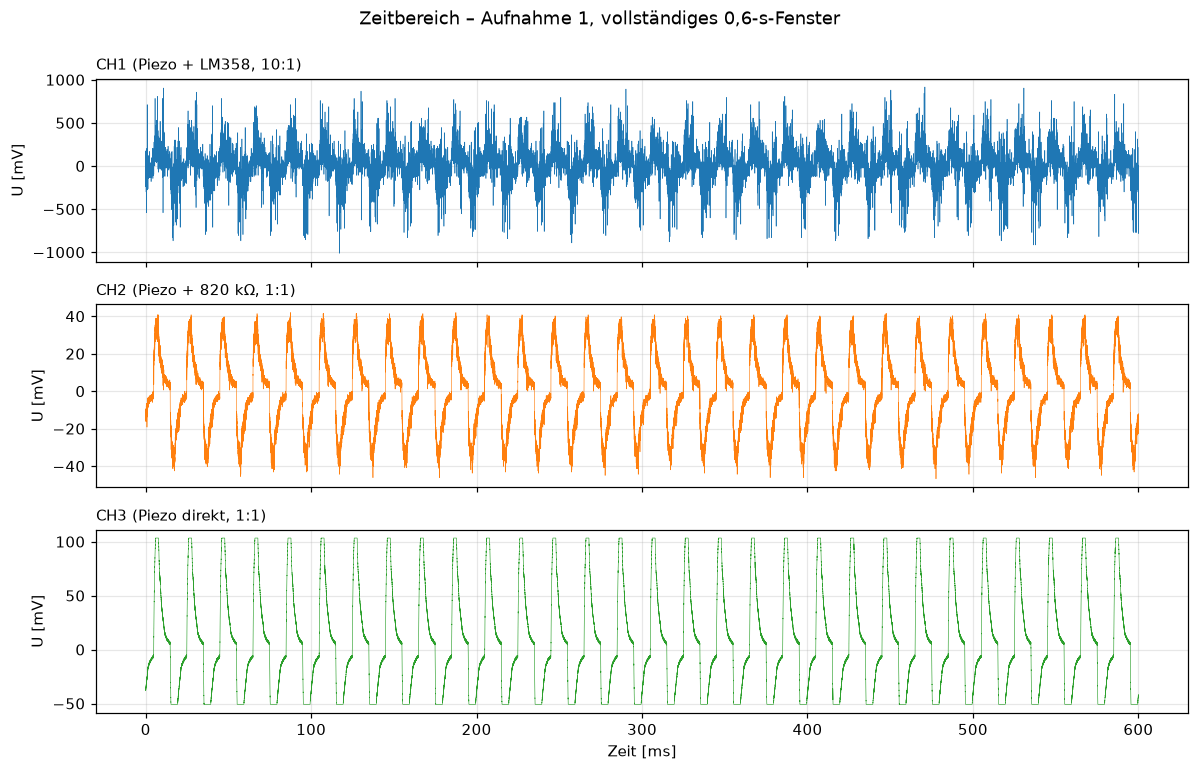

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, ch in zip(axes, fa.CHANNELS):
    v = captures[ch]["caps"][0]
    t = np.arange(len(v)) / captures[ch]["rate"]
    ax.plot(t * 1e3, v * 1e3, color=CHANNEL_COLORS[ch], lw=0.4)
    ax.set_ylabel("U [mV]")
    ax.set_title(CHANNEL_LABELS[ch], loc="left", fontsize=10)
axes[-1].set_xlabel("Time [ms]")
fig.suptitle("Time domain — capture 1, full 0.6 s window", y=0.995)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "channels_timeseries.png", bbox_inches="tight")
plt.show()


## 3. Frequency Domain (Mean Spectrum per Channel)


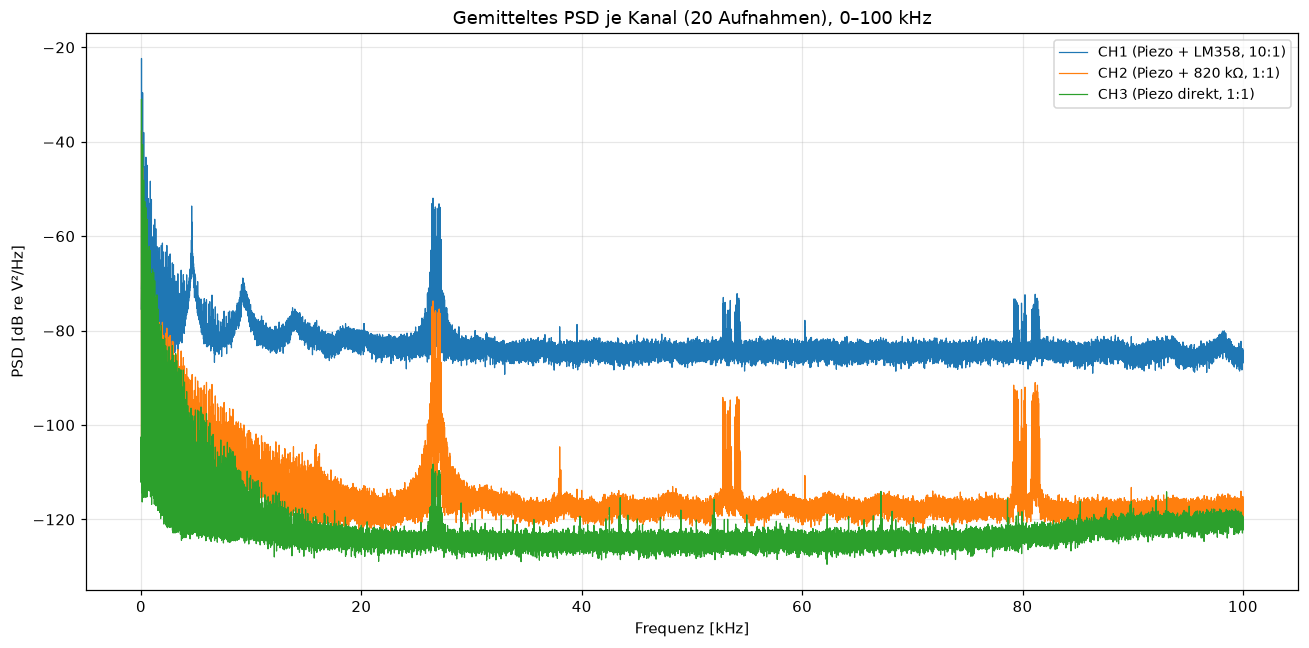

In [3]:
fig, ax = plt.subplots(figsize=(12, 6))
for ch in fa.CHANNELS:
    caps = captures[ch]["caps"]; rate = captures[ch]["rate"]
    freqs, mean_psd, _ = fa.average_psd(caps, rate)
    m = (freqs >= 20) & (freqs <= fa.MAX_FREQUENCY_HZ)
    ax.plot(freqs[m] / 1e3, 10 * np.log10(np.maximum(mean_psd[m], 1e-30)),
            color=CHANNEL_COLORS[ch], lw=0.8, label=CHANNEL_LABELS[ch])
ax.set_xlabel("Frequency [kHz]")
ax.set_ylabel("PSD [dB re V\u00b2/Hz]")
ax.set_title("Mean PSD per channel (20 captures), 0\u2013100 kHz")
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "channels_psd.png", bbox_inches="tight")
plt.show()


## 3b. Frequency Spectrum (Oscilloscope Style)

Same data as above, stacked per channel on a dark oscilloscope background.
Range 0–5 kHz; the five most prominent peaks per channel are annotated automatically.
Saved as `oscilloscope_spectrum.png` (reproduces
`experiment_plant_acoustic_emissions_20260621/oscilloscope_plots/oscilloscope_spectrum.png`
from the canonical 22.06. dataset at 500 kSa/s instead of 10 kSa/s).


In [ ]:
from scipy.signal import find_peaks

OSC_COLORS  = {1: '#00ff00', 2: '#ffff00', 3: '#00ffff'}
OSC_LABELS  = {1: 'CH1 (Piezo + LM358, 10:1)', 2: 'CH2 (Piezo + 820 Ω, 1:1)', 3: 'CH3 (Piezo direct, 1:1)'}
FREQ_MAX_HZ = 5_000
N_PEAKS     = 5

fig, axes = plt.subplots(3, 1, figsize=(14, 10))
fig.patch.set_facecolor('#1a1a1a')
fig.suptitle('Plant AE — Frequency Spectrum per Channel (0–5 kHz)', color='white', fontsize=13, fontweight='bold')

for ax, ch in zip(axes, fa.CHANNELS):
    ax.set_facecolor('#0a0a0a')
    caps = captures[ch]['caps']; rate = captures[ch]['rate']
    freqs, mean_psd, _ = fa.average_psd(caps, rate)
    amp_db = 10 * np.log10(np.maximum(mean_psd, 1e-30))

    mask = (freqs >= 20) & (freqs <= FREQ_MAX_HZ)
    f_m, a_m = freqs[mask], amp_db[mask]

    ax.plot(f_m, a_m, color=OSC_COLORS[ch], linewidth=1.2, alpha=0.9)
    ax.set_ylabel('Amplitude (dB re V²/Hz)', color='white', fontsize=9)
    ax.set_title(OSC_LABELS[ch], color='white', fontsize=10, fontweight='bold')
    ax.tick_params(colors='white', labelsize=8)
    for spine in ax.spines.values(): spine.set_edgecolor('#555')
    ax.grid(True, alpha=0.2, color='gray')

    for xv in np.arange(0, FREQ_MAX_HZ + 1, 500):
        ax.axvline(xv, color='gray', alpha=0.15, linewidth=0.4)

    pk_idx, _ = find_peaks(a_m, prominence=3, distance=max(1, int(50 / (freqs[1]-freqs[0]))))
    top_pk = sorted(pk_idx, key=lambda i: a_m[i], reverse=True)[:N_PEAKS]
    for pi in top_pk:
        ax.axvline(f_m[pi], color='red', alpha=0.5, linestyle='--', linewidth=0.8)
        ax.annotate(
            f'{f_m[pi]:.0f} Hz',
            xy=(f_m[pi], a_m[pi]),
            xytext=(f_m[pi] + 80, a_m[pi] - 4),
            color='yellow', fontsize=7, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='yellow', lw=0.8),
            clip_on=True,
        )

axes[-1].set_xlabel('Frequency (Hz)', color='white', fontsize=10)
fig.tight_layout(rect=[0, 0, 1, 0.96])
out_path = OUTPUT_DIR / 'oscilloscope_spectrum.png'
fig.savefig(out_path, dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
print(f'Saved: {out_path}')
plt.show()


## 4. Amplitude Statistics per Channel


In [4]:
rows = []
for ch in fa.CHANNELS:
    allv = np.concatenate(captures[ch]["caps"])
    rows.append({"Channel": CHANNEL_LABELS[ch],
                 "Mean [mV]": round(allv.mean() * 1e3, 3),
                 "Std [mV]": round(allv.std() * 1e3, 3),
                 "RMS [mV]": round(np.sqrt(np.mean(allv**2)) * 1e3, 3),
                 "Min [mV]": round(allv.min() * 1e3, 2),
                 "Max [mV]": round(allv.max() * 1e3, 2)})
pd.DataFrame(rows)


,Kanal,Mittel [mV],Std [mV],RMS [mV],Min [mV],Max [mV]
0,"CH1 (Piezo + LM358, 10:1)",7.138,143.193,143.371,-1012.59,952.32
1,"CH2 (Piezo + 820 kΩ, 1:1)",0.373,22.908,22.911,-50.37,57.56
2,"CH3 (Piezo direkt, 1:1)",7.251,49.135,49.667,-50.76,103.33


## 5. Channel Comparison: Common vs. Independent Components

If the same signal appears on all channels, pairwise time-series correlation
is high — the hallmark of **common-mode coupling** (shared noise source),
not locally generated emission at a single sensor.
Discrimination between local emission and common-mode interference is a
standard requirement in multi-channel AE measurement (De Roo et al., 2016).


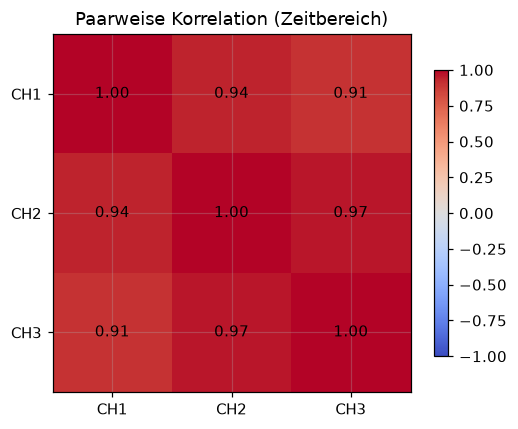

In [5]:
# Pairwise Pearson correlation of the first capture (DC-removed)
n = min(len(captures[ch]["caps"][0]) for ch in fa.CHANNELS)
sig = {ch: captures[ch]["caps"][0][:n] - captures[ch]["caps"][0][:n].mean() for ch in fa.CHANNELS}
corr = np.ones((3, 3))
for a, ca in enumerate(fa.CHANNELS):
    for b, cb in enumerate(fa.CHANNELS):
        corr[a, b] = np.corrcoef(sig[ca], sig[cb])[0, 1]

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(3), [f"CH{c}" for c in fa.CHANNELS])
ax.set_yticks(range(3), [f"CH{c}" for c in fa.CHANNELS])
for a in range(3):
    for b in range(3):
        ax.text(b, a, f"{corr[a, b]:.2f}", ha="center", va="center")
ax.set_title("Pairwise correlation (time domain)")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "channel_correlation.png", bbox_inches="tight")
plt.show()


## 6. Summary

- All three electrically distinct channels show a **very similar spectrum**
  with the same sharp lines.
- Pairwise time-series correlation is clearly non-zero — strong evidence for
  a **common-mode component**.
- Conclusion: peaks that appear identically on all channels **must not** be
  interpreted as plant AE from this passive measurement alone.

Quantitative validation (repeatability, coherence, SNR, sensor resonance flag)
and detailed scientific interpretation follow in
`02_frequency_characterization.ipynb`.
